# TP 1 · Identifier un locuteur à partir d’une réplique

Quels indices permettent d’attribuer une réplique à un locuteur, et jusqu’où mes résultats permettent-ils de généraliser ?

Je construis un classifieur à partir de Tiny Shakespeare. Je veux comprendre ce que le texte apporte à la prédiction, puis vérifier comment mes choix influencent la mesure.

Je pars de l’idée que les mots et leurs associations peuvent distinguer les locuteurs. Je garde aussi une autre explication possible, celle d’indices liés aux interlocuteurs et au contexte de l’histoire.

## 0. Environnement

Je fixe la graine à 42 pour retrouver les mêmes tirages dans cet environnement. Je conserve les versions utilisées afin de pouvoir distinguer un changement de résultat d’un changement de logiciel.

In [1]:
# Je prépare les bibliothèques et fixe les tirages aléatoires.
import re
import sys
from collections import Counter

import sklearn
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

from IPython.display import HTML, Image, display

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environnement prêt.")
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__}")
print(f"NumPy {np.__version__} | pandas {pd.__version__} | graine {RANDOM_STATE}")


def pourcentage(partie: float | pd.Series, total: float) -> float | pd.Series:
    """Exprime une partie en pourcentage du total."""
    return 100 * partie / total

Environnement prêt.
Python 3.14.7 | scikit-learn 1.9.0
NumPy 2.5.3 | pandas 3.0.5 | graine 42


## 1. Charger le corpus

Je charge le texte brut pour observer sa structure avant de choisir une cible. Je vérifie sa taille et un extrait, car un téléchargement réussi ne garantit pas que j’ai reçu les données attendues.

In [2]:
# Je charge Tiny Shakespeare et affiche un premier extrait.
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

texte = urllib.request.urlopen(URL).read().decode("utf-8")

print(f"{len(texte):,} caractères")
print(f"{len(texte.splitlines()):,} lignes")
print("\n--- 300 premiers caractères ---\n")
print(texte[:300])

1,115,394 caractères
40,000 lignes

--- 300 premiers caractères ---

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


Je retrouve 40 000 lignes et 1 115 394 caractères. Les noms placés avant les répliques me donnent une piste pour construire des exemples étiquetés.

## 2. Observer la structure avant de coder

Je lis un extrait plus long pour vérifier si les séparateurs et les noms reviennent de la même manière. Cette observation prépare le découpage, sans prouver que tous les blocs suivent ce format.

In [3]:
# Je lis un second extrait pour examiner les limites entre répliques.
print(texte[1000:2500])

Second Citizen:
Would you proceed especially against Caius Marcius?

All:
Against him first: he's a very dog to the commonalty.

Second Citizen:
Consider you what services he has done for his country?

First Citizen:
Very well; and could be content to give him good
report fort, but that he pays himself with being proud.

Second Citizen:
Nay, but speak not maliciously.

First Citizen:
I say unto you, what he hath done famously, he did
it to that end: though soft-conscienced men can be
content to say it was for his country he did it to
please his mother and to be partly proud; which he
is, even till the altitude of his virtue.

Second Citizen:
What he cannot help in his nature, you account a
vice in him. You must in no way say he is covetous.

First Citizen:
If I must not, I need not be barren of accusations;
he hath faults, with surplus, to tire in repetition.
What shouts are these? The other side o' the city
is risen: why stay we prating here? to the Capitol!

All:
Come, come.

First C

> *Mes observations :*
>
> Dans ces extraits, une ligne vide sépare les blocs. Un en-tête comme « First Citizen: » précède le texte de la réplique.
>
> Je peux donc récupérer le locuteur comme étiquette, sans ajouter une annotation manuelle. J’entraîne ensuite un classifieur supervisé sur ces étiquettes déjà présentes dans le texte.
>
> L’extraction automatique des étiquettes ne suffit pas à qualifier cette tâche d’auto-supervisée. Ici, la cible vient des noms de locuteurs indiqués dans le corpus.

## 3. Construire le jeu de données étiqueté

Je conserve le parseur pour garder la même tâche. Il accepte un en-tête conforme à son expression régulière, suivi d’au moins une ligne de texte, puis rassemble cette réplique.

Un bloc vide, un en-tête seul ou un nom hors du motif est ignoré. Je compte ces rejets pour préciser ce que représente le jeu obtenu.

In [4]:
# Je conserve les blocs reconnus par le parseur.
def parser_repliques(txt: str) -> pd.DataFrame:
    """Extrait les répliques dont l’en-tête respecte le motif attendu."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])
        if entete and len(parties) > 1:
            lignes.append({
                "locuteur": entete.group(1).strip(),
                "replique": " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


df = parser_repliques(texte)

print(f"{len(df):,} répliques extraites")
print(f"{df['locuteur'].nunique()} locuteurs distincts")
display(df.head(10))
blocs_non_vides = [bloc for bloc in texte.split("\n\n") if bloc.strip()]
print(f"Blocs non vides : {len(blocs_non_vides)}")
print(f"Blocs non retenus : {len(blocs_non_vides) - len(df)}")

7,094 répliques extraites
297 locuteurs distincts


,locuteur,replique
0,First Citizen,"Before we proceed any further, hear me speak."
1,All,"Speak, speak."
2,First Citizen,You are all resolved rather to die than to fam...
3,All,Resolved. resolved.
4,First Citizen,"First, you know Caius Marcius is chief enemy t..."
5,All,"We know't, we know't."
6,First Citizen,"Let us kill him, and we'll have corn at our ow..."
7,All,"No more talking on't; let it be done: away, away!"
8,Second Citizen,"One word, good citizens."
9,First Citizen,"We are accounted poor citizens, the patricians..."


Blocs non vides : 7222
Blocs non retenus : 128


Je récupère 7 094 répliques et 297 étiquettes distinctes, en laissant 128 blocs non retenus. Je ne traite pas ces rejets comme des répliques valides perdues sans les examiner.

Ces noms ne garantissent pas une identité unique entre pièces. Je prédis les étiquettes telles qu’elles apparaissent, sans fusionner leurs variantes ni reconstruire les scènes.

### 3.1 Explorer la distribution

Je regarde les effectifs avant de fixer le nombre de classes. Je mesure aussi les longueurs, car une réplique courte peut contenir peu d’indices même si son locuteur est fréquent.

In [5]:
# Je mesure les effectifs et les longueurs sur les répliques extraites.
print("\n--- 20 locuteurs les plus fréquents ---\n")
print(df['locuteur'].value_counts().head(20))
print("\n--- 20 locuteurs les moins fréquents ---\n")
print(df['locuteur'].value_counts().tail(20))
print("\n--- Nombre de locuteurs avec une seule réplique ---\n")
print((df['locuteur'].value_counts() == 1).sum())

print("\n--- Distribution de la longueur des répliques (en nombre de mots) ---\n")
df['longueur_replique'] = df['replique'].apply(lambda x: len(x.split()))
print(df['longueur_replique'].describe())


--- 20 locuteurs les plus fréquents ---

locuteur
GLOUCESTER           211
DUKE VINCENTIO       189
MENENIUS             161
ROMEO                160
PETRUCHIO            155
CORIOLANUS           148
KING RICHARD III     137
ISABELLA             127
JULIET               124
LEONTES              124
SICINIUS             117
KING EDWARD IV       109
QUEEN ELIZABETH      105
LUCIO                101
KING RICHARD II       98
WARWICK               98
BRUTUS                91
HENRY BOLINGBROKE     90
TRANIO                90
BUCKINGHAM            89
Name: count, dtype: int64

--- 20 locuteurs les moins fréquents ---

locuteur
LADY  CAPULET      1
Musician           1
Third Musician     1
JOHN MORTIMER      1
Nobleman           1
Soldier            1
First Messenger    1
Time               1
Shepard            1
DUKE               1
Players            1
ALL                1
HORTENSIA          1
KATARINA           1
PHILIP             1
JOSEPH             1
NICHOLAS           1
Haberdasher   

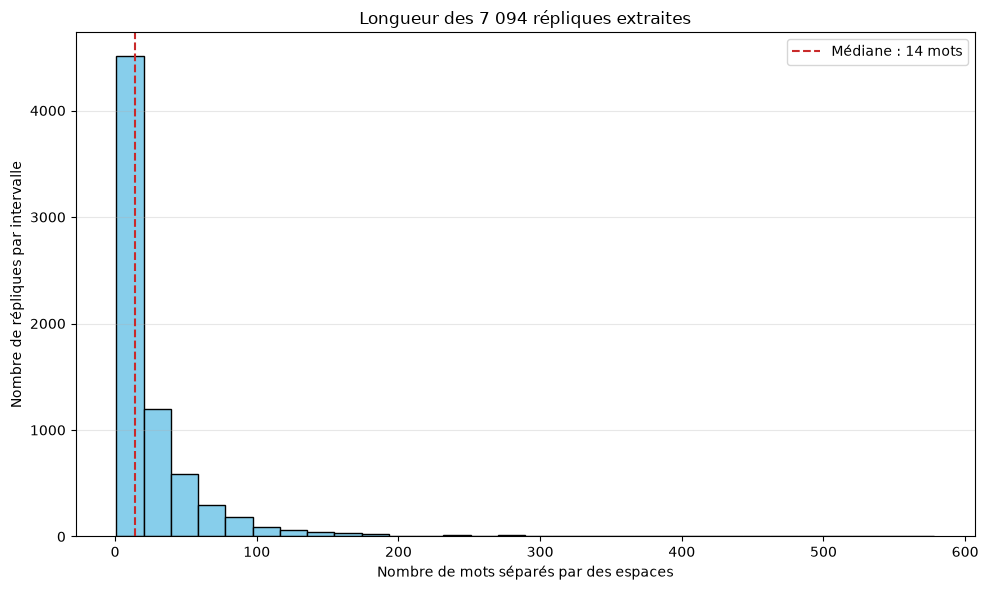

In [6]:
# Je représente toutes les longueurs et repère leur médiane.
plt.figure(figsize=(10, 6))
plt.hist(df['longueur_replique'], bins=30, color='skyblue', edgecolor='black')
mediane_longueur = df['longueur_replique'].median()
plt.axvline(mediane_longueur, color='#c92a2a', linestyle='--',
            label=f'Médiane : {mediane_longueur:g} mots')
plt.title(f'Longueur des {len(df):,} répliques extraites'.replace(',', ' '))
plt.xlabel('Nombre de mots séparés par des espaces')
plt.ylabel('Nombre de répliques par intervalle')
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

> *Mes observations :*
>
> Les effectifs sont déséquilibrés et 51 étiquettes n’ont qu’une réplique. Les conserver rendrait leur évaluation fragile, car je ne pourrais pas répartir chacune entre apprentissage et test.
>
> La médiane vaut 14 mots, contre une moyenne d’environ 27,2 et un maximum de 578. La distribution présente donc une longue queue vers les grandes répliques.
>
> Je m’attends à des vecteurs creux, car chaque réplique utilise une petite partie du vocabulaire. Je vérifierai cette intuition après la vectorisation, dans la section 6.

## 4. Définir la tâche

Je compare les effectifs obtenus avec des seuils de cinq et dix mots, pour plusieurs nombres de locuteurs. Je veux garder assez d’exemples par classe sans limiter la tâche à quelques personnages.

Mon hypothèse est qu’une réplique plus longue offre davantage d’indices lexicaux. Cette comparaison décrit les données conservées, mais ne mesure pas l’effet du seuil sur la classification.

In [7]:
# Je compare les sous-corpus avant de fixer la tâche.
longueurs = df['replique'].str.split().str.len()
comparaisons = []
for seuil in (5, 10):
    frequences = df.loc[longueurs >= seuil, 'locuteur'].value_counts()
    for n in (5, 10, 20):
        effectifs = frequences.head(n)
        comparaisons.append({
            'Seuil minimal (mots)': seuil,
            'Locuteurs': len(effectifs),
            'Répliques': effectifs.sum(),
            'Effectifs min–max': f'{effectifs.min()}–{effectifs.max()}',
            'Classe majoritaire (%)': round(pourcentage(effectifs.max(), effectifs.sum()), 1),
            'Distribution': effectifs.tolist(),
        })

comparaisons = pd.DataFrame(comparaisons)
with pd.option_context('display.max_colwidth', None):
    display(comparaisons)

,Seuil minimal (mots),Locuteurs,Répliques,Effectifs min–max,Classe majoritaire (%),Distribution
0,5,5,761,126–196,25.8,"[196, 165, 141, 133, 126]"
1,5,10,1318,107–196,14.9,"[196, 165, 141, 133, 126, 116, 115, 110, 109, 107]"
2,5,20,2194,78–196,8.9,"[196, 165, 141, 133, 126, 116, 115, 110, 109, 107, 99, 98, 95, 95, 86, 83, 82, 80, 80, 78]"
3,10,5,550,94–129,23.5,"[129, 125, 107, 95, 94]"
4,10,10,962,78–129,13.4,"[129, 125, 107, 95, 94, 87, 85, 82, 80, 78]"
5,10,20,1581,54–129,8.2,"[129, 125, 107, 95, 94, 87, 85, 82, 80, 78, 75, 71, 66, 62, 61, 60, 58, 57, 55, 54]"


> *Mes choix :*
>
> Je retiens dix locuteurs parmi les plus fréquents après filtrage, avec au moins dix mots par réplique. Ce choix garde 962 exemples, avec 78 à 129 répliques par classe.
>
> La classe majoritaire représente 13,4 %, contre 14,9 % avec le seuil de cinq mots et dix locuteurs. Le déséquilibre est modéré, mais le filtrage ne garantit pas l’équilibre.
>
> J’accepte de perdre des exemples pour travailler sur des textes plus longs. Je n’ai pas comparé les scores selon le seuil, donc je garde son bénéfice attendu comme hypothèse.

In [8]:
# Je fixe le sous-corpus et conserve les étiquettes telles quelles.
seuil = 10
nb_locuteurs = 10
locuteurs = df.loc[longueurs >= seuil, 'locuteur'].value_counts().head(nb_locuteurs).index

donnees = df.loc[
    (longueurs >= seuil) & (df['locuteur'].isin(locuteurs)),
    ['replique', 'locuteur']
].copy()

print(donnees['locuteur'].value_counts())
print(f"\n{len(donnees)} exemples retenus")

locuteur
GLOUCESTER         129
DUKE VINCENTIO     125
MENENIUS           107
PETRUCHIO           95
ROMEO               94
CORIOLANUS          87
JULIET              85
LEONTES             82
ISABELLA            80
KING RICHARD II     78
Name: count, dtype: int64

962 exemples retenus


## 5. Séparer apprentissage et test

Je définis le sous-corpus avant le découpage, puis réserve 20 % des répliques au test. La stratification cherche à conserver les proportions des classes, avec les écarts imposés par les effectifs entiers.

Le vocabulaire et les IDF seront ajustés uniquement sur l’entraînement. Les apprendre sur tout le corpus ferait intervenir le test dans la représentation et compromettrait son rôle d’évaluation.

Cette tâche reste conditionnée par le choix des locuteurs sur le corpus complet. Le découpage par réplique ne sépare pas les scènes ou les pièces.

In [9]:
# Je répartis les répliques et vérifie les proportions par classe.
X_train, X_test, y_train, y_test = train_test_split(
    donnees['replique'], donnees['locuteur'],
    test_size=0.2, stratify=donnees['locuteur'], random_state=RANDOM_STATE
)

print(f"train : {len(X_train)} exemples")
print(f"test  : {len(X_test)} exemples")

# Classes
classes = y_train.unique()
print(f"Classes : {classes}")

# Verification de la stratification
print("\n--- Vérification de la stratification ---\n")
train_counts = y_train.value_counts()
test_counts = y_test.value_counts()
stratification_check = pd.DataFrame({
    'Train': train_counts,
    'Test': test_counts,
    'Train (%)': pourcentage(train_counts, len(y_train)),
    'Test (%)': pourcentage(test_counts, len(y_test)),
})
print(stratification_check)

train : 769 exemples
test  : 193 exemples
Classes : <StringArray>
[     'CORIOLANUS',      'GLOUCESTER',       'PETRUCHIO',         'LEONTES',
          'JULIET',           'ROMEO',  'DUKE VINCENTIO', 'KING RICHARD II',
        'ISABELLA',        'MENENIUS']
Length: 10, dtype: str

--- Vérification de la stratification ---

                 Train  Test  Train (%)   Test (%)
locuteur                                          
CORIOLANUS          70    17   9.102731   8.808290
DUKE VINCENTIO     100    25  13.003901  12.953368
GLOUCESTER         103    26  13.394018  13.471503
ISABELLA            64    16   8.322497   8.290155
JULIET              68    17   8.842653   8.808290
KING RICHARD II     62    16   8.062419   8.290155
LEONTES             66    16   8.582575   8.290155
MENENIUS            85    22  11.053316  11.398964
PETRUCHIO           76    19   9.882965   9.844560
ROMEO               75    19   9.752926   9.844560


In [10]:
# Je vérifie la séparation des indices et des textes exacts.
indices_communs = X_train.index.intersection(X_test.index)
textes_communs = set(X_train).intersection(X_test)
print(f'Indices communs : {len(indices_communs)}')
print(f'Textes identiques entre les deux ensembles : {len(textes_communs)}')
assert len(indices_communs) == 0
assert len(textes_communs) == 0

Indices communs : 0
Textes identiques entre les deux ensembles : 0


Je dispose de 769 répliques d’entraînement et de 193 répliques de test, sans texte exactement identique entre les deux. Ce contrôle ne détecte ni les reformulations ni le contexte partagé.

Je conserve ce découpage pour les expériences suivantes. Les résultats décriront des répliques de ce sous-corpus, sans établir une généralisation à de nouvelles pièces.

## 6. Représenter le texte

Je choisis des mots seuls et des bigrammes pour garder une partie de l’ordre local. Je regroupe les variantes de casse et conserve les mots grammaticaux, qui peuvent fournir des indices.

Je garde les termes présents dans au moins deux répliques d’entraînement pour limiter les variables propres à un seul exemple. Ce seuil porte sur les documents, pas sur le nombre total d’occurrences.

Les paramètres retenus sont les suivants :

| Paramètre | Choix et raison |
|---|---|
| `lowercase=True` | Regrouper les variantes de casse |
| `ngram_range=(1, 2)` | Représenter mots seuls et couples de tokens consécutifs |
| `min_df=2` | Garder les termes présents dans au moins deux répliques d’entraînement |
| `max_df=1.0` | Ne pas écarter un terme pour sa fréquence documentaire élevée |
| `stop_words=None` | Ne pas retirer une liste de mots grammaticaux |
| `sublinear_tf=True` | Atténuer les répétitions avec `1 + log(tf)` |

Je garde ces réglages pour comparer les modèles. Leur intérêt individuel reste une hypothèse, puisque je ne les fais pas varier un par un.

In [11]:
# Je construis le vocabulaire sur l’entraînement puis transforme le test.
vectoriseur = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=1.0,
    stop_words=None,
    sublinear_tf=True,
)

Xtr = vectoriseur.fit_transform(X_train)  # fit_transform sur le train
Xte = vectoriseur.transform(X_test)  # transform sur le test

print(f"Taille du vocabulaire : {len(vectoriseur.vocabulary_):,}")
print(f"Matrice train : {Xtr.shape}")
print(f"Matrice test  : {Xte.shape}")
print(f"Valeurs non nulles : {pourcentage(Xtr.nnz, Xtr.shape[0] * Xtr.shape[1]):.4f} %")

Taille du vocabulaire : 5,915
Matrice train : (769, 5915)
Matrice test  : (193, 5915)
Valeurs non nulles : 0.8338 %


In [12]:
# Je mesure le stockage sans créer de matrice dense.
nombre_cases = Xtr.shape[0] * Xtr.shape[1]
memoire_dense = nombre_cases * Xtr.dtype.itemsize
memoire_creuse = Xtr.data.nbytes + Xtr.indices.nbytes + Xtr.indptr.nbytes
print(f'Valeurs nulles : {pourcentage(nombre_cases - Xtr.nnz, nombre_cases):.4f} %')
print(f'Type numérique : {Xtr.dtype}')
print(f'Mémoire dense théorique : {memoire_dense:,} octets')
print(f'Tableaux creux data, indices et indptr : {memoire_creuse:,} octets')
print(f'Rapport dense / tableaux creux : {memoire_dense / memoire_creuse:.1f}')
print(f'Normalisation : {vectoriseur.norm} | IDF lissé : {vectoriseur.smooth_idf}')

Valeurs nulles : 99.1662 %
Type numérique : float64
Mémoire dense théorique : 36,389,080 octets
Tableaux creux data, indices et indptr : 458,204 octets
Rapport dense / tableaux creux : 79.4
Normalisation : l2 | IDF lissé : True


> *Mes observations :*
>
> Le vocabulaire comporte 5 915 termes et seuls 0,8338 % des coefficients d’entraînement sont non nuls. Mon intuition sur les vecteurs creux se vérifie sur ces données.
>
> La version dense demanderait environ 36,4 Mo pour les valeurs en `float64`. Je conserve le format creux pour éviter de stocker les zéros, sans en déduire un gain de temps non mesuré.
>
> Je distingue aussi la normalisation L2 de chaque réplique d’une standardisation par moyenne et écart-type. Les statistiques apprises sur le corpus sont ici le vocabulaire et les IDF.

In [13]:
# Je vérifie les tokens réellement produits par le découpage par défaut.
exemple_tokens = "I am, I have, I'll bring"
print(f'Exemple : {exemple_tokens}')
print(f'Tokens : {vectoriseur.build_tokenizer()(exemple_tokens.lower())}')
print(f'Mots et bigrammes : {vectoriseur.build_analyzer()(exemple_tokens)}')

Exemple : I am, I have, I'll bring
Tokens : ['am', 'have', 'll', 'bring']
Mots et bigrammes : ['am', 'have', 'll', 'bring', 'am have', 'have ll', 'll bring']


Je pensais illustrer les bigrammes avec « I am » et « I have ». Le découpage retire pourtant « I », car il ne conserve que les tokens d’au moins deux caractères.

L’apostrophe sépare aussi les morceaux de « I’ll », dont « ll » est conservé. L’absence de liste de mots à supprimer ne signifie donc pas que tous les mots originaux survivent.

In [14]:
# Je regarde les termes aux IDF les plus faibles et les plus élevés.

idf_values = vectoriseur.idf_  # Récupère les valeurs IDF
# Trie les indices des valeurs IDF pour obtenir les 15 plus faibles et les 15 plus fortes
indices_plus_faibles = np.argsort(idf_values)[:15]
indices_plus_fortes = np.argsort(idf_values)[-15:]

print("\n--- 15 termes avec IDF le plus faible ---\n")
for idx in indices_plus_faibles:
    print(f"{vectoriseur.get_feature_names_out()[idx]} : {idf_values[idx]:.4f}")

print("\n--- 15 termes avec IDF le plus élevé ---\n")
for idx in indices_plus_fortes:
    print(f"{vectoriseur.get_feature_names_out()[idx]} : {idf_values[idx]:.4f}")


--- 15 termes avec IDF le plus faible ---

the : 1.5261
and : 1.5371
to : 1.5506
of : 1.8352
that : 1.8626
you : 1.9527
in : 1.9800
my : 2.0224
not : 2.0480
is : 2.0934
me : 2.1209
with : 2.1370
for : 2.1451
it : 2.2083
be : 2.2214

--- 15 termes avec IDF le plus élevé ---

lived : 6.5478
ll bring : 6.5478
ll go : 6.5478
ll have : 6.5478
ll hear : 6.5478
ll no : 6.5478
ll say : 6.5478
ll try : 6.5478
ll turn : 6.5478
loathed : 6.5478
lodge : 6.5478
loins : 6.5478
long and : 6.5478
light love : 6.5478
youthful : 6.5478


In [15]:
# Je relie quelques IDF au nombre de répliques d’entraînement contenant le terme.
frequences_documentaires = np.asarray((Xtr.copy() > 0).sum(axis=0)).ravel()
for terme in ('the', 'and', 'to', 'lived', 'll bring'):
    colonne = vectoriseur.vocabulary_[terme]
    nb_documents = int(frequences_documentaires[colonne])
    print(f'{terme} : {nb_documents}/{len(X_train)} répliques, '
          f'{pourcentage(nb_documents, len(X_train)):.1f} %, '
          f'IDF = {vectoriseur.idf_[colonne]:.4f}')

the : 454/769 répliques, 59.0 %, IDF = 1.5261
and : 449/769 répliques, 58.4 %, IDF = 1.5371
to : 443/769 répliques, 57.6 %, IDF = 1.5506
lived : 2/769 répliques, 0.3 %, IDF = 6.5478
ll bring : 2/769 répliques, 0.3 %, IDF = 6.5478


« the » apparaît dans 454 des 769 répliques d’entraînement, soit environ 59 %. Il est fréquent, mais ne figure pas dans presque toutes les répliques.

Je m’attendais initialement à des bigrammes plus fréquents et à un IDF plus faible. Un couple précis exige pourtant la présence de ses deux tokens consécutifs.

« lived » et « ll bring » apparaissent chacun dans deux répliques et partagent donc le même IDF. Leur rareté ne suffit pas à établir qu’ils caractérisent un locuteur.

### 6.1 Suivre une valeur TF–IDF

Je prends la première réplique d’entraînement et son premier token conservé pour vérifier le calcul. Je reconstruis les poids de cette ligne, car la normalisation dépend de tous ses termes.

In [16]:
# Je compte les termes de la première réplique sans ajuster de nouvel objet.
demo_texte = X_train.iloc[0]
demo_analyseur = vectoriseur.build_analyzer()
demo_termes = demo_analyseur(demo_texte)
demo_comptages = Counter(demo_termes)
demo_token = next(t for t in demo_termes if ' ' not in t and t in vectoriseur.vocabulary_)
demo_colonne = vectoriseur.vocabulary_[demo_token]
demo_tf = demo_comptages[demo_token]
demo_df = int(frequences_documentaires[demo_colonne])
print(f'Réplique {X_train.index[0]} : {demo_texte}')
print(f'Token suivi : {demo_token!r} | occurrences : {demo_tf}')
print(f'Présence dans l’entraînement : {demo_df}/{len(X_train)} répliques')

Réplique 364 : To brag unto them, thus I did, and thus; Show them the unaching scars which I should hide, As if I had received them for the hire Of their breath only!
Token suivi : 'to' | occurrences : 1
Présence dans l’entraînement : 443/769 répliques


In [17]:
# Je reconstruis le poids logarithmique, l’IDF lissé et la normalisation L2.
demo_tf_log = 1 + np.log(demo_tf)
demo_idf = 1 + np.log((1 + len(X_train)) / (1 + demo_df))
demo_poids = np.array([
    (1 + np.log(n)) * vectoriseur.idf_[vectoriseur.vocabulary_[t]]
    for t, n in demo_comptages.items() if t in vectoriseur.vocabulary_
])
demo_norme = np.linalg.norm(demo_poids)
demo_valeur = demo_tf_log * demo_idf / demo_norme
print(f'TF logarithmique : 1 + log({demo_tf}) = {demo_tf_log:.6f}')
print(f'IDF lissé : 1 + log((1 + {len(X_train)}) / (1 + {demo_df})) = {demo_idf:.6f}')
print(f'Norme L2 de tous les poids retenus : {demo_norme:.6f}')
print(f'Valeur TF–IDF : {demo_valeur:.8f} | matrice : {Xtr[0, demo_colonne]:.8f}')
assert np.isclose(demo_idf, vectoriseur.idf_[demo_colonne], rtol=1e-12, atol=1e-12)
assert np.isclose(demo_valeur, Xtr[0, demo_colonne], rtol=1e-12, atol=1e-12)

TF logarithmique : 1 + log(1) = 1.000000
IDF lissé : 1 + log((1 + 769) / (1 + 443)) = 1.550566
Norme L2 de tous les poids retenus : 27.710143
Valeur TF–IDF : 0.05595662 | matrice : 0.05595662


L’accord vérifie ce calcul sur la ligne choisie. Les répétitions passent par un logarithme, puis la normalisation partage le poids entre tous les termes présents.

Je comprends ainsi pourquoi multiplier un coefficient du classifieur par le nombre brut d’occurrences ne donnera pas sa contribution au score.

## 7. Modéliser

### 7.1 Mesurer deux références simples

Je commence par des prédictions qui n’utilisent pas le texte. La classe majoritaire et un tirage selon les fréquences d’entraînement me donnent deux références pour interpréter les scores.

Ces références exploitent la distribution des étiquettes, sans apprendre de relation entre mots et locuteurs. Elles ne constituent pas des bornes garanties pour les modèles suivants.

In [18]:
# Je mesure les deux modèles naïfs sur le même test.
for strategie in ('most_frequent', 'stratified'):
    baseline = DummyClassifier(strategy=strategie, random_state=RANDOM_STATE)
    baseline.fit(Xtr, y_train)
    predictions = baseline.predict(Xte)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions, average='macro', zero_division=0)
    print(f"{strategie} : accuracy = {accuracy:.3f}, F1 = {f1:.3f}")

most_frequent : accuracy = 0.135, F1 = 0.024
stratified : accuracy = 0.119, F1 = 0.115


> *Mes observations :*
>
> La classe majoritaire obtient une accuracy de 0,135 et un F1 macro de 0,024. Sa réussite sur une seule classe explique pourquoi ces deux métriques racontent des choses différentes.
>
> Le tirage stratifié obtient 0,119 en accuracy et 0,115 en F1 macro pour cette graine. Je n’interprète pas ce tirage unique comme la performance moyenne de toutes les prédictions aléatoires.

### 7.2 Comparer deux modèles linéaires

Je choisis la régression logistique et LinearSVC pour travailler directement avec les vecteurs creux. Ils combinent les mêmes variables, mais apprennent leurs coefficients avec des objectifs différents.

Je garde le découpage et la représentation fixes pour comparer ces configurations. Les réglages par défaut ne constituent pas une recherche équivalente du meilleur modèle pour chaque méthode.

Je conserve `class_weight=None` car le déséquilibre observé est modéré. Je vérifierai les résultats par classe, mais je ne teste pas ici l’effet d’une pondération équilibrée.

In [19]:
# Je conserve les mêmes données et entraîne les deux configurations.
modeles = {
    'LogisticRegression': LogisticRegression(max_iter=1000, class_weight=None),
    'LinearSVC': LinearSVC(
        max_iter=5000, class_weight=None, random_state=RANDOM_STATE
    ),
}

resultats = {}
for nom, modele in modeles.items():
    modele.fit(Xtr, y_train)
    resultats[nom] = modele.predict(Xte)

## 8. Évaluer et analyser

### 8.1 Lire les métriques ensemble

Je mesure avec l’accuracy la proportion totale de réponses correctes. La précision décrit la fiabilité des prédictions d’une classe, tandis que le rappel mesure la part de ses exemples retrouvés.

Le F1 combine précision et rappel par leur moyenne harmonique. Je privilégie le F1 macro pour donner le même poids à chaque locuteur, tout en gardant les autres métriques.

L’agrégation pondérée utilise les effectifs réels des classes. L’accuracy reste correcte, mais une valeur globale peut masquer des résultats très différents selon les locuteurs.

In [20]:
# Je compare les scores globaux et les résultats par locuteur.
scores = []
for nom, predictions in resultats.items():
    ligne = {'Modèle': nom, 'Accuracy': accuracy_score(y_test, predictions)}
    for moyenne in ('macro', 'weighted'):
        ligne[f'Précision {moyenne}'] = precision_score(
            y_test, predictions, average=moyenne, zero_division=0)
        ligne[f'Rappel {moyenne}'] = recall_score(
            y_test, predictions, average=moyenne, zero_division=0)
        ligne[f'F1 {moyenne}'] = f1_score(
            y_test, predictions, average=moyenne, zero_division=0)
    scores.append(ligne)
    print(f"\n{nom}")
    print(classification_report(y_test, predictions, digits=3, zero_division=0))

comparaison = pd.DataFrame(scores).set_index('Modèle')
display(comparaison.round(3))


LogisticRegression
                 precision    recall  f1-score   support

     CORIOLANUS      0.778     0.412     0.538        17
 DUKE VINCENTIO      0.300     0.600     0.400        25
     GLOUCESTER      0.354     0.654     0.459        26
       ISABELLA      0.800     0.250     0.381        16
         JULIET      0.462     0.353     0.400        17
KING RICHARD II      0.750     0.188     0.300        16
        LEONTES      1.000     0.438     0.609        16
       MENENIUS      0.500     0.500     0.500        22
      PETRUCHIO      0.316     0.316     0.316        19
          ROMEO      0.375     0.316     0.343        19

       accuracy                          0.425       193
      macro avg      0.563     0.403     0.425       193
   weighted avg      0.532     0.425     0.425       193


LinearSVC
                 precision    recall  f1-score   support

     CORIOLANUS      0.667     0.706     0.686        17
 DUKE VINCENTIO      0.457     0.640     0.533       

,Accuracy,Précision macro,Rappel macro,F1 macro,Précision weighted,Rappel weighted,F1 weighted
Modèle,,,,,,,
LogisticRegression,0.425,0.563,0.403,0.425,0.532,0.425,0.425
LinearSVC,0.565,0.574,0.558,0.563,0.571,0.565,0.565


Sur ce test, LinearSVC obtient un F1 macro de 0,563, contre 0,425 pour la régression logistique. Son accuracy vaut 0,565 et dépasse les deux références mesurées.

Je retiens LinearSVC pour examiner ses erreurs parce qu’il obtient le meilleur F1 macro des deux configurations. Ce choix utilise le test, donc je considère cette comparaison comme exploratoire.

### 8.2 Lire la matrice de confusion

Je cherche maintenant où se concentrent les erreurs de LinearSVC. Les lignes représentent les étiquettes réelles et les colonnes les prédictions, avec un effectif dans chaque case.

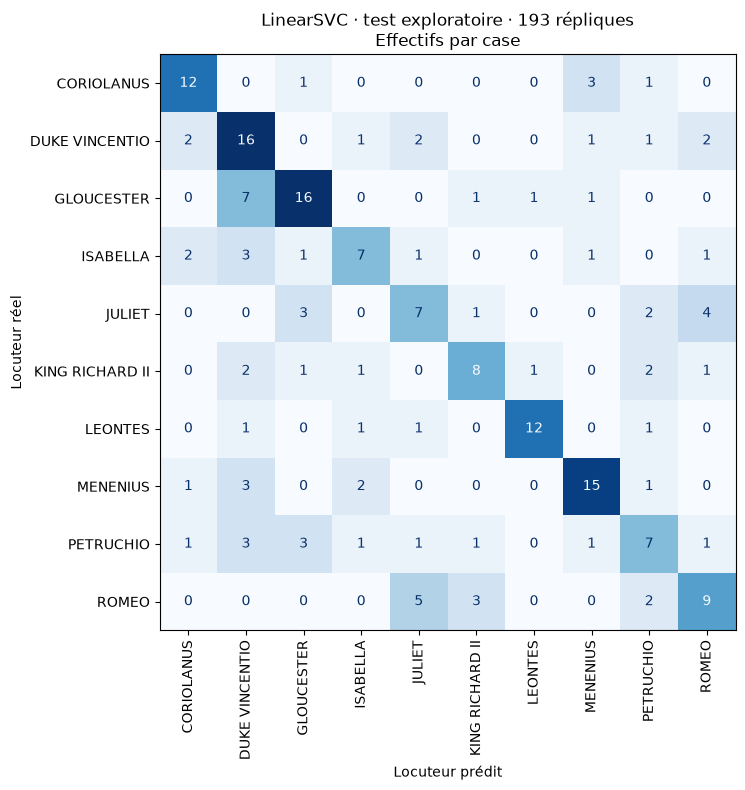

In [21]:
# Je conserve les effectifs et l’ordre des classes de la matrice de confusion.
meilleur = comparaison['F1 macro'].idxmax() # Sélection exploratoire sur le test.

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, resultats[meilleur],
    cmap='Blues', values_format='d', xticks_rotation=90,
    colorbar=False, ax=ax,
)
ax.set(title=f'{meilleur} · test exploratoire · {len(y_test)} répliques\nEffectifs par case',
       xlabel='Locuteur prédit', ylabel='Locuteur réel')
plt.tight_layout()
plt.show()

In [22]:
# Je vérifie les effectifs utilisés dans mon analyse de la matrice.
matrice_svc = pd.DataFrame(
    confusion_matrix(y_test, resultats['LinearSVC'], labels=modeles['LinearSVC'].classes_),
    index=modeles['LinearSVC'].classes_, columns=modeles['LinearSVC'].classes_,
)
for reel, predit in (('JULIET', 'ROMEO'), ('ROMEO', 'JULIET'),
                     ('GLOUCESTER', 'DUKE VINCENTIO'), ('DUKE VINCENTIO', 'GLOUCESTER')):
    print(f'{reel} → {predit} : {matrice_svc.loc[reel, predit]}')
for locuteur in ('LEONTES', 'PETRUCHIO', 'JULIET', 'DUKE VINCENTIO'):
    correctes = int(matrice_svc.loc[locuteur, locuteur])
    reelles = int(matrice_svc.loc[locuteur].sum())
    predites = int(matrice_svc[locuteur].sum())
    print(f'{locuteur} : {correctes} correctes / {reelles} réelles / {predites} prédites, '
          f'rappel {pourcentage(correctes, reelles):.1f} %, '
          f'précision {pourcentage(correctes, predites):.1f} %')
assert matrice_svc.to_numpy().sum() == len(y_test)
assert np.isclose(np.trace(matrice_svc) / len(y_test),
                  accuracy_score(y_test, resultats['LinearSVC']))

JULIET → ROMEO : 4
ROMEO → JULIET : 5
GLOUCESTER → DUKE VINCENTIO : 7
DUKE VINCENTIO → GLOUCESTER : 0
LEONTES : 12 correctes / 16 réelles / 14 prédites, rappel 75.0 %, précision 85.7 %
PETRUCHIO : 7 correctes / 19 réelles / 17 prédites, rappel 36.8 %, précision 41.2 %
JULIET : 7 correctes / 17 réelles / 17 prédites, rappel 41.2 %, précision 41.2 %
DUKE VINCENTIO : 16 correctes / 25 réelles / 35 prédites, rappel 64.0 %, précision 45.7 %


> *Mes observations :*
>
> LEONTES atteint un rappel de 75 %, avec 12 répliques correctes sur 16. PETRUCHIO atteint 36,8 % et JULIET 41,2 %, mais ces différences ne prouvent pas une cause lexicale précise.
>
> Je compte quatre répliques de JULIET attribuées à ROMEO et cinq dans le sens inverse. Un vocabulaire ou un contexte partagé pourrait contribuer à ces confusions.
>
> Sept répliques de GLOUCESTER vont vers DUKE VINCENTIO, sans erreur inverse. DUKE VINCENTIO est prédit 35 fois pour 25 exemples réels, avec 16 réponses correctes et une précision de 45,7 %.

### 8.3 Examiner les erreurs et les coefficients

Je lis les quinze premières erreurs dans l’ordre du test, sans choisir uniquement celles qui soutiennent mon hypothèse. Cet échantillon sert à chercher des explications, sans représenter nécessairement toutes les erreurs.

Je regarde ensuite les coefficients positifs les plus élevés. Ils indiquent quels termes favorisent une classe dans le modèle, mais leur contribution dépend aussi de la valeur TF–IDF de la réplique.

In [23]:
# Les quinze premières erreurs de LinearSVC, dans l’ordre du test.
erreurs_svc = pd.DataFrame({
    'Réplique': X_test,
    'Locuteur réel': y_test,
    'Locuteur prédit': resultats['LinearSVC'],
})
erreurs_svc = erreurs_svc.loc[
    erreurs_svc['Locuteur réel'] != erreurs_svc['Locuteur prédit']
]
display(HTML(
    '<style>#erreurs-svc td {white-space:normal; max-width:600px; text-align:left;}</style>'
    + erreurs_svc.head(15).to_html(table_id='erreurs-svc', escape=True)
))

,Réplique,Locuteur réel,Locuteur prédit
3009,"And I'll still stay, to have thee still forget, Forgetting any other home but this.",ROMEO,JULIET
3338,"O God!--O nurse, how shall this be prevented? My husband is on earth, my faith in heaven; How shall that faith return again to earth, Unless that husband send it me from heaven By leaving earth? comfort me, counsel me. Alack, alack, that heaven should practise stratagems Upon so soft a subject as myself! What say'st thou? hast thou not a word of joy? Some comfort, nurse.",JULIET,ROMEO
2294,"I am in health, I breathe, and see thee ill.",KING RICHARD II,PETRUCHIO
3344,"Well, thou hast comforted me marvellous much. Go in: and tell my lady I am gone, Having displeased my father, to Laurence' cell, To make confession and to be absolved.",JULIET,ROMEO
2875,"Not I, believe me: you have dancing shoes With nimble soles: I have a soul of lead So stakes me to the ground I cannot move.",ROMEO,JULIET
3378,"Love give me strength! and strength shall help afford. Farewell, dear father!",JULIET,ROMEO
2300,"Right, you say true: as Hereford's love, so his; As theirs, so mine; and all be as it is.",KING RICHARD II,LEONTES
1323,"Your eyes drop millstones, when fools' eyes drop tears: I like you, lads; about your business straight; Go, go, dispatch.",GLOUCESTER,DUKE VINCENTIO
6229,Who knows not where a wasp does wear his sting? In his tail.,PETRUCHIO,GLOUCESTER
1579,"I say, without characters, fame lives long. Thus, like the formal vice, Iniquity, I moralize two meanings in one word.",GLOUCESTER,MENENIUS


Je ne pense pas pouvoir attribuer avec certitude les cinq premières répliques sans leur contexte. « nurse », « husband » et « Laurence » donnent des indices dans les exemples de JULIET.

« I am in health, I breathe, and see thee ill » me paraît plus difficile à attribuer. Cet examen explique une difficulté possible, sans mesurer un plafond de performance ni valider le seuil de dix mots.

In [24]:
# Les dix poids positifs les plus élevés pour chaque locuteur.
termes_svc = vectoriseur.get_feature_names_out() # Récupère les termes du vocabulaire
coefficients_svc = []
for locuteur, poids in zip(modeles['LinearSVC'].classes_, modeles['LinearSVC'].coef_):
    indices = np.argsort(poids)[::-1] # Trie les indices des poids par ordre décroissant
    indices = indices[poids[indices] > 0][:10] # 10 poids positifs les plus élevés
    coefficients_svc.append({
        'Locuteur': locuteur,
        'Termes et poids': [(termes_svc[i], round(float(poids[i]), 3)) for i in indices],
    })
coefficients_svc = pd.DataFrame(coefficients_svc).set_index('Locuteur')
display(HTML(
    '<style>#coefficients-svc td {white-space:normal; max-width:680px; text-align:left;}</style>'
    + coefficients_svc.to_html(table_id='coefficients-svc', escape=True)
))

,Termes et poids
Locuteur,
CORIOLANUS,"[(them, 1.401), (rome, 1.038), (voices, 0.841), (volsces, 0.811), (their, 0.778), (again, 0.768), (in rome, 0.749), (hurt, 0.731), (my, 0.724), (aufidius, 0.721)]"
DUKE VINCENTIO,"[(provost, 1.472), (angelo, 1.293), (you, 1.287), (duke, 1.193), (the duke, 1.146), (friar, 1.119), (himself, 1.1), (him, 1.016), (claudio, 0.994), (your, 0.92)]"
GLOUCESTER,"[(clarence, 1.45), (king, 1.313), (edward, 1.213), (the king, 1.051), (shore, 0.925), (lord, 0.903), (warwick, 0.895), (imprisonment, 0.839), (well, 0.832), (myself, 0.825)]"
ISABELLA,"[(my brother, 1.805), (brother, 1.469), (heaven, 1.254), (but, 0.872), (your honour, 0.82), (yes, 0.811), (alas, 0.734), (most, 0.706), (as, 0.705), (pluck, 0.696)]"
JULIET,"[(romeo, 1.623), (love, 0.958), (may be, 0.944), (nurse, 0.889), (learn, 0.785), (have thee, 0.74), (then have, 0.731), (on my, 0.723), (my true, 0.689), (hands, 0.686)]"
KING RICHARD II,"[(king, 1.3), (bolingbroke, 1.217), (our, 1.118), (cousin, 1.088), (high, 0.908), (make, 0.831), (sorrow, 0.784), (yours and, 0.751), (norfolk, 0.696), (uncle, 0.672)]"
LEONTES,"[(paulina, 1.447), (camillo, 1.211), (her, 0.936), (perform, 0.859), (bastard, 0.812), (at my, 0.792), (she, 0.725), (polixenes, 0.725), (hermione, 0.706), (thou, 0.65)]"
MENENIUS,"[(marcius, 1.674), (work, 1.172), (he, 1.15), (what then, 0.953), (speak, 0.925), (cominius, 0.89), (be gone, 0.844), (noble, 0.832), (you, 0.816), (tribunes, 0.814)]"
PETRUCHIO,"[(kate, 2.645), (signior, 1.033), (father, 0.939), (and, 0.935), (her, 0.922), (knock, 0.914), (now by, 0.824), (gown, 0.794), (cap, 0.715), (blow, 0.697)]"


> *Mes observations :*
>
> ROMEO et JULIET ont des effectifs proches, avec 94 et 85 répliques dans le sous-corpus. Le terme « love » reçoit un coefficient positif élevé dans les deux classes.
>
> GLOUCESTER et DUKE VINCENTIO ont aussi des effectifs proches, avec 129 et 125 répliques. Ce comptage ne suffit pas à expliquer les erreurs allant vers DUKE VINCENTIO.
>
> Les noms « kate », « romeo », « paulina » et « camillo » figurent aussi parmi les termes les plus favorables aux classes correspondantes. Ils soutiennent l’hypothèse d’indices liés aux personnages mentionnés.
>
> Je ne peux pas en déduire que le modèle reconnaît seulement une pièce, ni qu’il identifie un style personnel. Les coefficients seuls ne séparent pas ces explications.

Pour l’erreur n° 1241, j’avais attribué un rôle à « you » et « him ». Je vérifie leurs occurrences et leurs contributions réelles avant de conserver cette explication.

In [25]:
# Je décompose les scores de la réplique 1241 sans modifier le modèle ajusté.
demo_position = X_test.index.get_loc(1241)
demo_ligne = Xte[demo_position]
demo_modele = modeles['LinearSVC']
demo_noms = demo_modele.classes_
demo_comptes_erreur = Counter(vectoriseur.build_analyzer()(X_test.loc[1241]))
demo_contributions = demo_modele.coef_[:, demo_ligne.indices] * demo_ligne.data
demo_scores = demo_contributions.sum(axis=1) + demo_modele.intercept_
demo_attendus = demo_modele.decision_function(demo_ligne)[0]
demo_prediction = demo_noms[demo_scores.argmax()]
print(f"Occurrences dans la réplique : you = {demo_comptes_erreur['you']}, "
      f"him = {demo_comptes_erreur['him']}")
for demo_classe in ('GLOUCESTER', 'DUKE VINCENTIO'):
    demo_i = np.flatnonzero(demo_noms == demo_classe)[0]
    print(f'{demo_classe} : somme des contributions = {demo_contributions[demo_i].sum():.6f}, '
          f'biais = {demo_modele.intercept_[demo_i]:.6f}, score = {demo_scores[demo_i]:.6f}')
print(f'Classe réelle : {y_test.loc[1241]} | prédiction reconstruite : {demo_prediction}')
assert np.allclose(demo_scores, demo_attendus, rtol=1e-10, atol=1e-12)
assert demo_prediction == resultats['LinearSVC'][demo_position]

Occurrences dans la réplique : you = 3, him = 1
GLOUCESTER : somme des contributions = 0.053325, biais = -0.663856, score = -0.610530
DUKE VINCENTIO : somme des contributions = 0.524647, biais = -0.867225, score = -0.342578
Classe réelle : GLOUCESTER | prédiction reconstruite : DUKE VINCENTIO


In [26]:
# Je compare les contributions à l’écart entre DUKE VINCENTIO et GLOUCESTER.
demo_duke = np.flatnonzero(demo_noms == 'DUKE VINCENTIO')[0]
demo_gloucester = np.flatnonzero(demo_noms == 'GLOUCESTER')[0]
demo_ecarts = demo_contributions[demo_duke] - demo_contributions[demo_gloucester]
demo_biais = demo_modele.intercept_[demo_duke] - demo_modele.intercept_[demo_gloucester]
demo_detail = pd.DataFrame({
    'Terme': termes_svc[demo_ligne.indices], 'TF–IDF': demo_ligne.data,
    'Contribution DUKE': demo_contributions[demo_duke],
    'Contribution GLOUCESTER': demo_contributions[demo_gloucester],
    'Écart DUKE moins GLOUCESTER': demo_ecarts,
}).set_index('Terme')
demo_ordre = demo_detail['Écart DUKE moins GLOUCESTER'].abs().sort_values().index[::-1]
display(demo_detail.loc[demo_ordre[:8]].round(6))
display(demo_detail.loc[['you', 'him']].round(6))
print(f'Somme sur tous les termes : {demo_ecarts.sum():.6f}')
print(f'Écart des biais : {demo_biais:.6f}')
print(f'Écart total des scores : {demo_scores[demo_duke] - demo_scores[demo_gloucester]:.6f}')
assert np.isclose(demo_ecarts.sum() + demo_biais,
                  demo_scores[demo_duke] - demo_scores[demo_gloucester], atol=1e-12)

,TF–IDF,Contribution DUKE,Contribution GLOUCESTER,Écart DUKE moins GLOUCESTER
Terme,,,,
you,0.120877,0.155615,-0.025684,0.181300
nor,0.200213,0.114422,-0.058720,0.173142
god,0.121530,-0.072238,0.098973,-0.171212
of your,0.131804,0.093689,-0.031533,0.125222
him,0.084085,0.085439,-0.035842,0.121281
would,0.092490,0.060230,-0.045210,0.105441
person,0.149889,-0.012724,0.079899,-0.092624
cannot,0.120675,-0.035978,0.041465,-0.077444


,TF–IDF,Contribution DUKE,Contribution GLOUCESTER,Écart DUKE moins GLOUCESTER
Terme,,,,
you,0.120877,0.155615,-0.025684,0.181300
him,0.084085,0.085439,-0.035842,0.121281


Somme sur tous les termes : 0.471322
Écart des biais : -0.203370
Écart total des scores : 0.267952


Je corrige mon comptage initial de « you », qui apparaît trois fois et non quatre. La décomposition vérifie aussi que les scores dépendent de l’ensemble des termes et du biais.

Les contributions expliquent le calcul local du modèle pour cette réplique. Elles ne prouvent pas la cause linguistique de l’erreur et ne permettent pas d’attribuer toute la décision à un mot.

> *Ma conclusion :*
>
> L’accuracy de 56,5 % décrit ce test de 193 répliques. Le vocabulaire vient de l’entraînement et aucun doublon exact ne traverse le découpage, mais le contexte du corpus reste partagé.
>
> J’ai aussi choisi LinearSVC d’après ce test. Je poursuis donc l’étude par validation croisée sur l’entraînement, sans présenter le test déjà consulté comme une évaluation finale indépendante.

## 9. Approfondir les comparaisons par validation croisée

Je veux savoir si les conclusions dépendent du découpage et des réglages. Je répartis les 769 répliques d’entraînement en cinq plis stratifiés, c’est-à-dire cinq groupes de validation successifs.

À chaque passage, le pipeline réapprend vocabulaire, IDF et coefficients sur les autres plis. Je mesure ainsi les performances sans laisser le pli de validation construire sa propre représentation.

Le schéma distingue cette procédure des consultations du test déjà effectuées. Le pipeline protège les transformations incluses, mais ne contrôle ni la définition de la tâche ni mes choix après consultation du test.

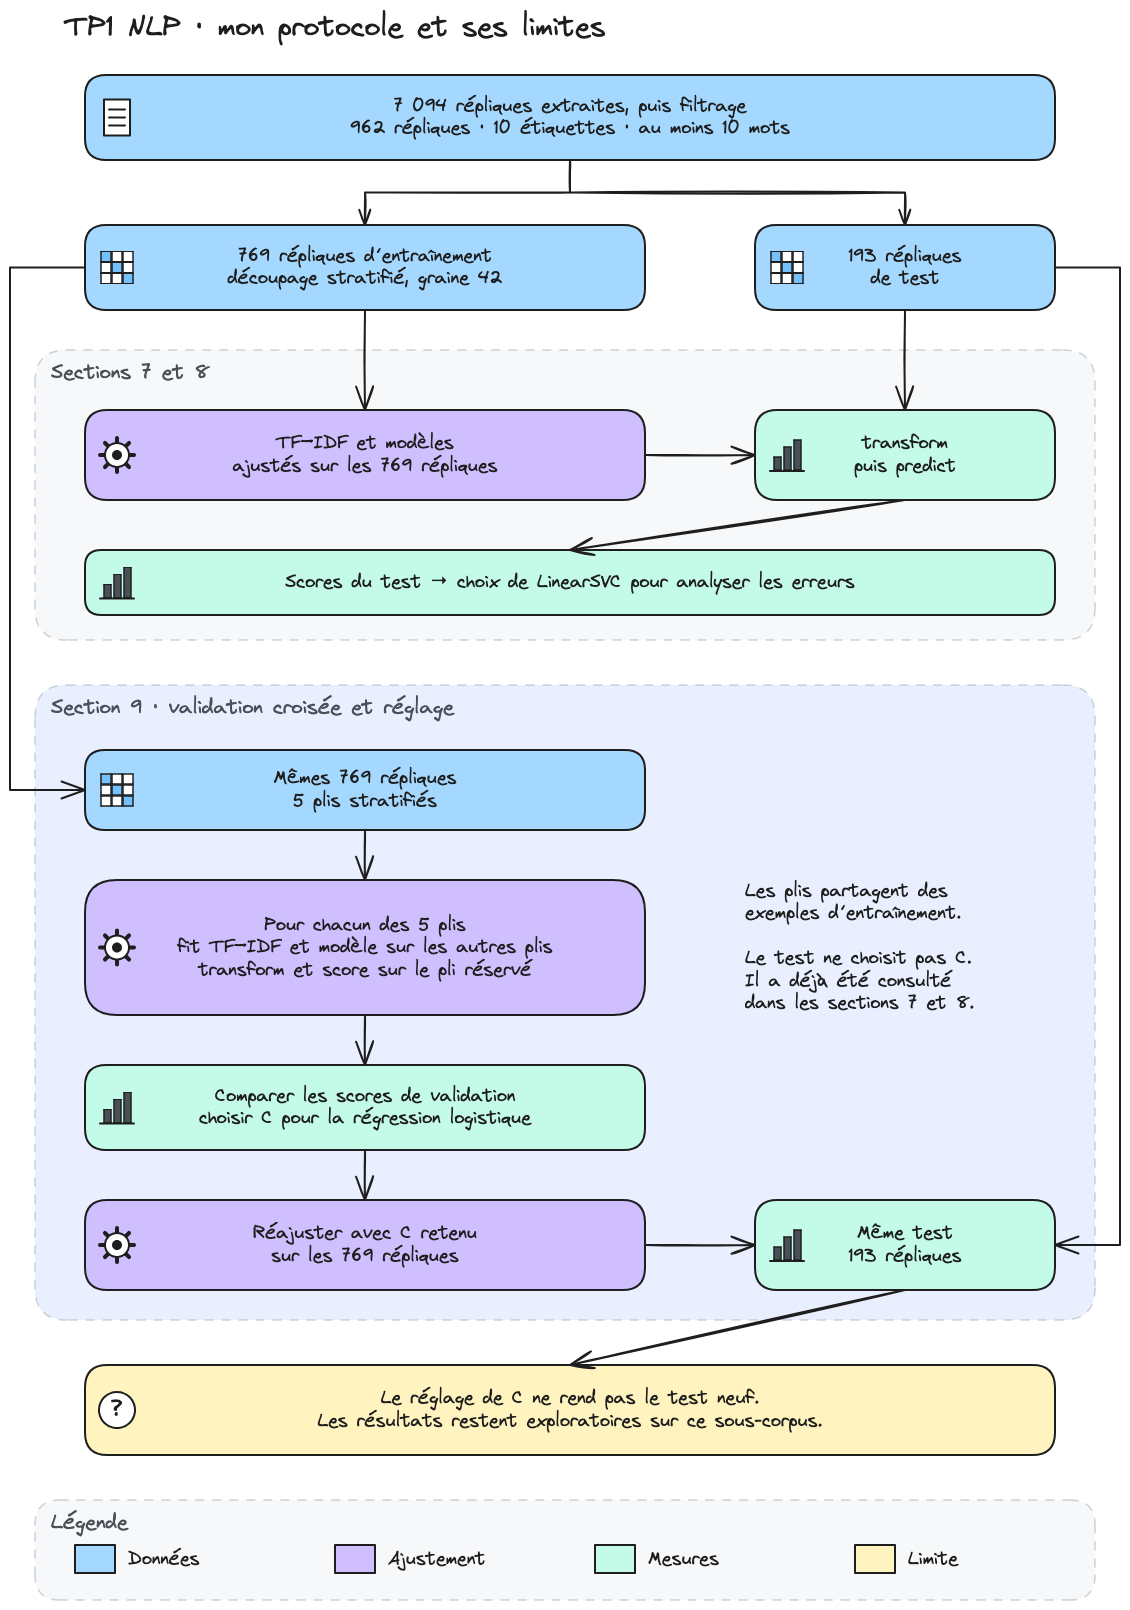

In [27]:
# Je rappelle le protocole et les consultations successives du même test.
display(Image(filename='diagrams/nlp/tp1_protocole.png', width=920))

In [28]:
# Je conserve les mêmes cinq plis pour chaque comparaison sur les mêmes exemples.
cv_9 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluer_cv(pipeline: Pipeline, textes=X_train, cibles=y_train) -> dict:
    """Résume les scores d’entraînement et de validation sur les cinq plis."""
    scores = cross_validate(
        pipeline, textes, cibles, cv=cv_9,
        scoring=('accuracy', 'f1_macro'), return_train_score=True, error_score='raise',
    )
    bilan = {}
    for cle, nom in (('accuracy', 'Accuracy'), ('f1_macro', 'F1 macro')):
        bilan[f'{nom} train'] = scores[f'train_{cle}'].mean()
        bilan[f'{nom} validation'] = scores[f'test_{cle}'].mean()
        bilan[f'{nom} écart-type'] = scores[f'test_{cle}'].std()
    return bilan

### 9.1 Mesurer la dispersion pour LinearSVC

Je reprends les paramètres de LinearSVC et du TF–IDF sans conserver leur ajustement précédent. Je compare les scores d’apprentissage et de validation pour voir si la séparation des exemples appris se retrouve ailleurs.

In [29]:
# 9.1 — Pipeline et validation croisée sur les 769 répliques du train.
pipeline_svc_9 = Pipeline([
    ('texte', clone(vectoriseur)),
    ('modele', clone(modeles['LinearSVC'])),
])  # clone reprend les paramètres, sans conserver l'entraînement précédent.
bilan_svc_9 = evaluer_cv(pipeline_svc_9)
display(pd.DataFrame([bilan_svc_9], index=['TF–IDF + LinearSVC']).round(3))

,Accuracy train,Accuracy validation,Accuracy écart-type,F1 macro train,F1 macro validation,F1 macro écart-type
TF–IDF + LinearSVC,1.0,0.492,0.037,1.0,0.482,0.035


> *Mes observations :*
>
> L’accuracy moyenne vaut 0,492 et le F1 macro moyen 0,482. Leurs écarts-types sur les cinq plis valent respectivement 0,037 et 0,035.
>
> Ces écarts-types décrivent la dispersion de cette validation croisée, sans constituer des intervalles de confiance. Les ensembles d’apprentissage se recouvrent, donc les cinq ajustements ne sont pas des répétitions indépendantes.
>
> Le F1 macro moyen d’apprentissage est affiché à 1,000 après arrondi. L’écart avec la validation indique une forte différence entre séparation des exemples appris et prédiction de nouvelles répliques.

### 9.2 Comparer TF–IDF et comptages

Je garde les mêmes plis, les mêmes règles de vocabulaire et les mêmes paramètres de LinearSVC. Je remplace le TF–IDF par les comptages bruts de `CountVectorizer`.

Cette substitution enlève ensemble les IDF, le logarithme des occurrences et la normalisation L2. Je compare deux représentations complètes, sans isoler l’effet des seuls IDF.

In [30]:
# 9.2 — Mêmes folds et même modèle, seule la représentation change.
parametres_bow_9 = {cle: vectoriseur.get_params()[cle] for cle in
                   ('lowercase', 'ngram_range', 'min_df', 'max_df', 'stop_words')}
pipeline_bow_9 = clone(pipeline_svc_9).set_params(
    texte=CountVectorizer(**parametres_bow_9))
representations_9 = pd.DataFrame({
    'TF–IDF': bilan_svc_9,
    'Bag of Words': evaluer_cv(pipeline_bow_9),
}).T
display(representations_9.round(3))

,Accuracy train,Accuracy validation,Accuracy écart-type,F1 macro train,F1 macro validation,F1 macro écart-type
TF–IDF,1.0,0.492,0.037,1.0,0.482,0.035
Bag of Words,1.0,0.399,0.042,1.0,0.386,0.042


> *Mes observations :*
>
> Le F1 macro moyen passe de 0,386 avec les comptages à 0,482 avec le TF–IDF. L’accuracy moyenne passe de 0,399 à 0,492 sur les mêmes cinq plis.
>
> Je mesure donc un avantage du TF–IDF dans cette comparaison. Je n’ai pas évalué la significativité de cet écart, ni réglé séparément la régularisation pour chaque représentation.

### 9.3 Passer de dix à cinq locuteurs

Je choisis les cinq locuteurs les plus fréquents dans l’entraînement, puis conserve les mêmes réglages du pipeline. Je veux observer ce qui change lorsque certaines classes concurrentes disparaissent.

Le sous-ensemble et ses plis changent aussi. Cette expérience ne permet donc pas d’attribuer toute la différence au seul nombre de classes.

In [31]:
# 9.3 — Les cinq locuteurs sont choisis uniquement à partir du train.
locuteurs_5_9 = y_train.value_counts().head(5).index
masque_5_9 = y_train.isin(locuteurs_5_9)
difficulte_9 = pd.DataFrame({
    5: {'Répliques': int(masque_5_9.sum()),
        **evaluer_cv(pipeline_svc_9, X_train.loc[masque_5_9], y_train.loc[masque_5_9])},
    10: {'Répliques': len(X_train), **bilan_svc_9},
}).T.rename_axis('Locuteurs').astype({'Répliques': int})
display(difficulte_9.round(3))
print(f"Cinq locuteurs retenus : {list(locuteurs_5_9)}")

,Répliques,Accuracy train,Accuracy validation,Accuracy écart-type,F1 macro train,F1 macro validation,F1 macro écart-type
Locuteurs,,,,,,,
5,439,1.0,0.642,0.051,1.0,0.644,0.050
10,769,1.0,0.492,0.037,1.0,0.482,0.035


Cinq locuteurs retenus : ['GLOUCESTER', 'DUKE VINCENTIO', 'MENENIUS', 'PETRUCHIO', 'ROMEO']


> *Mes observations :*
>
> Avec cinq locuteurs, je garde 439 répliques d’entraînement et j’obtiens une accuracy moyenne de 0,642. Avec dix locuteurs et 769 répliques, elle vaut 0,492.
>
> Le F1 macro moyen passe de 0,644 à 0,482, soit une baisse de 0,162 contre 0,150 pour l’accuracy. Les deux agrégations pondèrent différemment les erreurs, et les classes évaluées ont aussi changé.
>
> ROMEO reste parmi les cinq classes, tandis que JULIET en sort. Leur confusion devient impossible, ce qui illustre le changement de tâche sans démontrer la cause de tout le gain.

### 9.4 Faire varier la régularisation

Je reprends la régression logistique et compare trois valeurs de `C` sur les mêmes plis. Une valeur plus faible renforce la pénalisation des coefficients, ce qui peut limiter l’ajustement aux exemples appris.

Je retiens la valeur donnant le meilleur F1 macro moyen de validation parmi ces essais. Je garde aussi les scores d’apprentissage pour repérer une pénalisation éventuellement trop forte.

In [32]:
# 9.4 — Un C plus petit impose une régularisation plus forte.
pipeline_lr_9 = Pipeline([
    ('texte', clone(vectoriseur)),
    ('modele', clone(modeles['LogisticRegression'])),
])
regularisation_9 = pd.DataFrame({
    c_9: evaluer_cv(clone(pipeline_lr_9).set_params(modele__C=c_9))
    for c_9 in (0.1, 1, 10)
}).T.rename_axis('C')
display(regularisation_9.round(3))

# L'index est croissant : idxmax retient le plus petit C en cas d'égalité exacte.
meilleur_c_9 = regularisation_9.sort_index()['F1 macro validation'].idxmax()
print(f'C retenu sur la validation : {meilleur_c_9:g}')

,Accuracy train,Accuracy validation,Accuracy écart-type,F1 macro train,F1 macro validation,F1 macro écart-type
C,,,,,,
0.1,0.280,0.220,0.018,0.120,0.076,0.010
1.0,0.995,0.420,0.014,0.995,0.386,0.010
10.0,1.000,0.486,0.034,1.000,0.475,0.033


C retenu sur la validation : 10


Avec `C = 0,1`, le F1 macro moyen vaut 0,120 en apprentissage et 0,076 en validation. Ces deux scores faibles sont compatibles avec du sous-apprentissage pour ce réglage.

Le F1 macro de validation atteint 0,386 avec `C = 1` et 0,475 avec `C = 10`. Je retiens donc 10 parmi les valeurs testées, sans prétendre avoir trouvé un optimum global.

### 9.5 Réajuster la régression logistique retenue

Je réajuste cette configuration sur les 769 répliques d’entraînement, puis consulte à nouveau le même test. Le réglage de `C` repose sur la validation, mais ce test a déjà servi à comparer les premiers modèles.

In [33]:
# Je réévalue la régression logistique réglée sur le test déjà consulté.
modele_final_9 = clone(pipeline_lr_9).set_params(modele__C=meilleur_c_9)
modele_final_9.fit(X_train, y_train)
scores_finaux_9 = []
for ensemble_9, textes_9, cibles_9 in (
    ('Train', X_train, y_train), ('Test', X_test, y_test),
):
    predictions_9 = modele_final_9.predict(textes_9)
    scores_finaux_9.append({
        'Ensemble': ensemble_9, 'Répliques': len(textes_9),
        'Accuracy': accuracy_score(cibles_9, predictions_9),
        'F1 macro': f1_score(cibles_9, predictions_9, average='macro', zero_division=0),
    })
scores_finaux_9 = pd.DataFrame(scores_finaux_9).set_index('Ensemble')
display(scores_finaux_9.round(3))

,Répliques,Accuracy,F1 macro
Ensemble,,,
Train,769,1.000,1.000
Test,193,0.513,0.513


> *Mes observations :*
>
> Après réajustement, l’accuracy et le F1 macro sont affichés à 1,000 sur l’entraînement et à 0,513 sur le test. Cet écart indique du sur-apprentissage sur cette séparation.
>
> Le F1 macro de test dépasse les 0,425 de la régression logistique initiale, mais reste inférieur aux 0,563 de LinearSVC. La régression logistique réglée n’est donc pas le meilleur résultat exploratoire observé.
>
> La moyenne de validation et le score de test utilisent des exemples et des tailles d’apprentissage différents. Je ne les traite pas comme deux mesures interchangeables ni comme un plafond de performance.

## Bilan de ma démarche

> *Ma conclusion :*
>
> Les mots permettent de dépasser les deux références naïves sur ce sous-corpus. Les erreurs et les coefficients suggèrent des indices liés aux personnages mentionnés, sans démontrer une reconnaissance du style.
>
> Je dois vérifier le traitement réel avant d’interpréter les variables. L’exemple de « I am » et le calcul TF–IDF corrigent des raccourcis que les noms des paramètres ne suffisaient pas à voir.
>
> Je distingue désormais un coefficient global de sa contribution dans une réplique. De même, comparer deux scores demande de préciser les exemples, les classes et les réglages qui changent ensemble.
>
> Pour une prochaine étude, je figerais mes choix avant d’ouvrir un test indépendant. Ici, je conserve la trace de ses consultations et limite mes conclusions aux expériences réalisées.